# Task 4: Sales Prediction using Python
**MyDailyWork Data Science Internship**

Goal: predict sales from the money spent on TV, Radio and Newspaper advertising.

## Step 1: Importing the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Step 2: Reading the dataset

In [2]:
# Read Dataset  (in Google Colab use: "/content/Advertising.csv")
df = pd.read_csv("Advertising.csv")

# Remove an extra index column if the file has one
df = df.drop(columns=[c for c in df.columns if "Unnamed" in c])
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [3]:
df.shape

(200, 4)

In [4]:
# Missing values and basic statistics
print(df.isnull().sum())
df.describe()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


## Step 3: Exploring the data (charts)

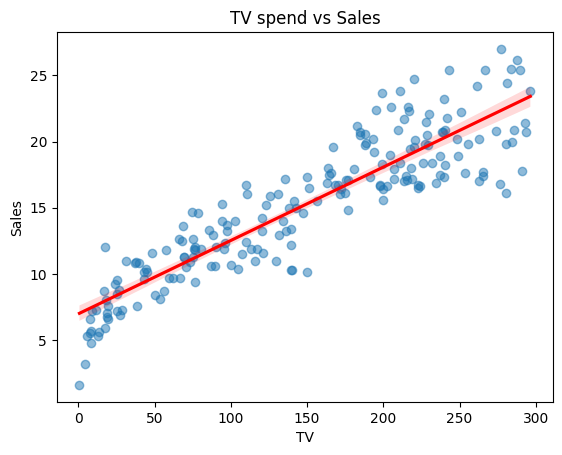

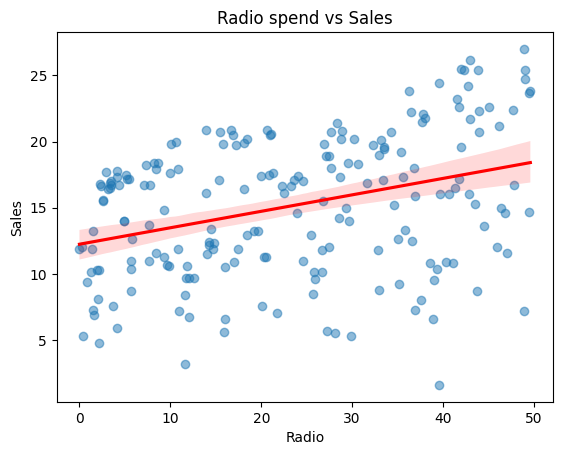

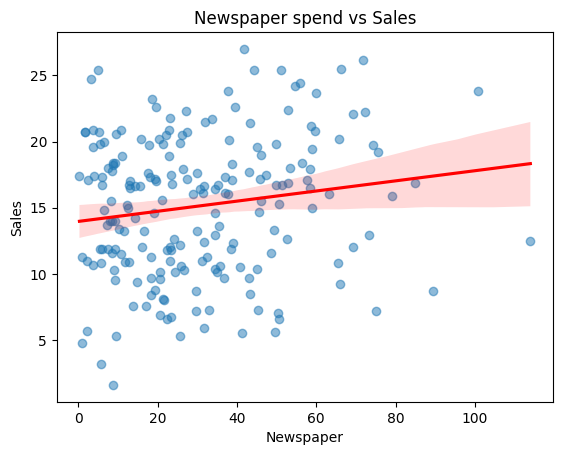

In [5]:
features = ["TV", "Radio", "Newspaper"]

# Money spent vs sales, one chart per channel
for col in features:
    sns.regplot(x=col, y="Sales", data=df, scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
    plt.title(col + " spend vs Sales")
    plt.show()

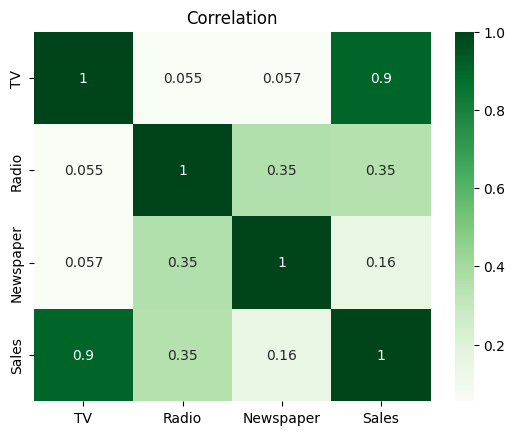

In [6]:
# Which column is most connected to Sales?
sns.heatmap(df.corr(), annot=True, cmap="Greens")
plt.title("Correlation")
plt.show()

## Step 4: Spliting the data

In [7]:
x = df[features]       # input features
y = df["Sales"]        # what we want to predict
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

## Step 5: Training the two models and comparing them

In [8]:
lr = LinearRegression()
lr.fit(x_train, y_train)

rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [9]:
# R2 (higher is better), MAE and RMSE (lower is better)
def show(name, y_pred):
    print(name)
    print("  R2   :", round(r2_score(y_test, y_pred), 3))
    print("  MAE  :", round(mean_absolute_error(y_test, y_pred), 3))
    print("  RMSE :", round(mean_squared_error(y_test, y_pred) ** 0.5, 3))

show("Just guess the average", [y_train.mean()] * len(y_test))
show("Linear Regression", lr.predict(x_test))
show("Random Forest", rf.predict(x_test))

Just guess the average
  R2   : -0.032
  MAE  : 4.932
  RMSE : 5.648
Linear Regression
  R2   : 0.906
  MAE  : 1.275
  RMSE : 1.705
Random Forest
  R2   : 0.955
  MAE  : 0.914
  RMSE : 1.183


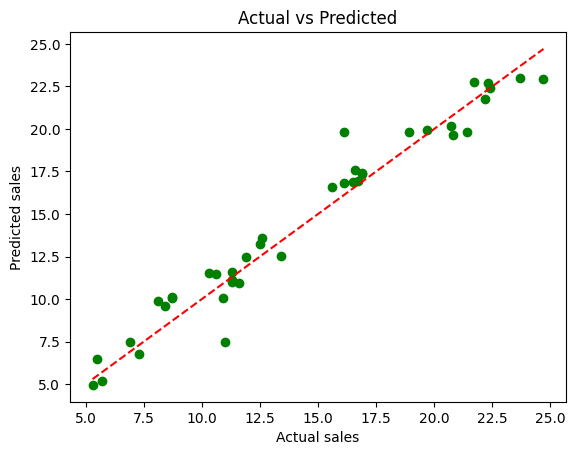

In [10]:
# Actual vs predicted for the Random Forest
y_pred = rf.predict(x_test)
plt.scatter(y_test, y_pred, color="green")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual sales")
plt.ylabel("Predicted sales")
plt.title("Actual vs Predicted")
plt.show()

## Step 6: Which channel pays off? (business insight)

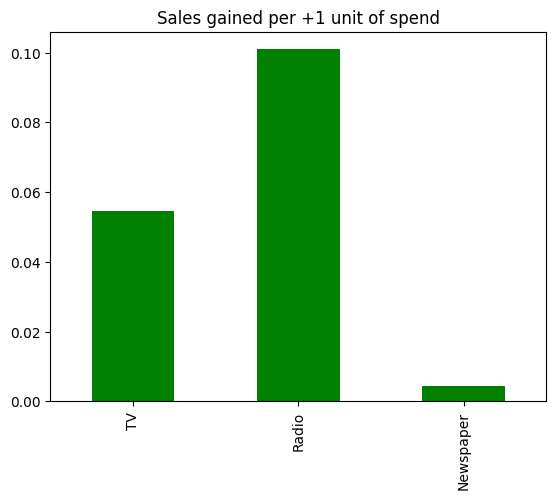

TV           0.054509
Radio        0.100945
Newspaper    0.004337
dtype: float64

In [11]:
# Linear Regression: how much do sales go up for +1 unit of spend?
coef = pd.Series(lr.coef_, index=features)
coef.plot(kind="bar", color="green")
plt.title("Sales gained per +1 unit of spend")
plt.show()
coef

In [12]:
# What-if: take the average budget and add 10 units to ONE channel
best = rf if r2_score(y_test, rf.predict(x_test)) > r2_score(y_test, lr.predict(x_test)) else lr

average_budget = x.mean()
base = best.predict(pd.DataFrame([average_budget]))[0]
print("Sales at average budget:", round(base, 2))

for col in features:
    more = average_budget.copy()
    more[col] = more[col] + 10
    print("+10 on", col, "-> sales change:", round(best.predict(pd.DataFrame([more]))[0] - base, 2))

Sales at average budget: 14.01
+10 on TV -> sales change: 2.49
+10 on Radio -> sales change: 1.45
+10 on Newspaper -> sales change: 0.17


## Step 7: Saving the best model

In [13]:
joblib.dump({
    "model": best,
    "features": features,
    "ranges": {c: (float(df[c].min()), float(df[c].max())) for c in features},
    "average_sales": float(df["Sales"].mean()),
}, "sales_model.pkl")
print("Model saved!")

Model saved!
